<a href="https://colab.research.google.com/github/Preetish-ko/Preetish-ko/blob/main/Guitar_Pick_up_guide.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Designing Guitar Amplification Pedals: A Physics & Circuit Guide

Guitar amplification pedals represent a beautiful marriage of linear and non-linear circuit components. They capture the raw, physical signal from a guitar pickup, process it through a series of analog components, and deliver a uniquely altered audio output.

While many online resources teach the isolated physics of circuits or string mechanics, this guide provides a cohesive, end-to-end mathematical and physical framework to design, simulate, and theorize your own guitar pedals.

---

### Notebook Roadmap
1. **The Physics of Guitar Pickups**: Modeling permanent magnets, copper windings, and spatial induction.
2. **Electromagnetic Induction**: Mathematical representation of string motion converting to voltage.
3. **The Equivalent RLC Circuit**: Simulating the electrical impedance, cable capacitance, and loading effects that define a pickup's native voice.
4. **Noise Mitigation**: Single coils vs. Humbucking coils.
5. **Acoustic and Physical Constraints**: The spatial filtering of pickup placement and string physics.
6. **The Linear & Non-Linear Circuit Engine**: Analyzing resistors, capacitors, inductors, and active components (transistors/op-amps) used to shape tone.

## 1. How a Guitar Pickup Works

At its core, a magnetic guitar pickup is a transducer consisting of three primary components:
1. **A Permanent Magnet** (typically Alnico or Ceramic)
2. **Steel Pole Pieces** (to direct the magnetic flux)
3. **A Fine Copper Coil** (often wound thousands of times around the bobbin)

Rather than sensing a magnetic field from the string directly, the permanent magnet magnetizes the nearby steel or nickel string. This transforms the vibrating string into its own moving temporary magnet. As the string oscillates, it perturbs the surrounding magnetic field, dynamically altering the magnetic flux passing through the copper coil.

---

## 2. Mathematical Modeling of Electromagnetic Induction

According to **Faraday's Law of Induction**, any change in magnetic flux ($\Phi_B$) through a coil of wire induces an electromotive force (voltage $V$) across its terminals:

$$V = -N \frac{d\Phi_B}{dt}$$

where $N$ is the number of wire turns.

### Key Physical Implications:
* **Winding Density ($N$)**: Increasing the number of turns directly scales the output voltage. However, it also raises the series DC resistance and coil self-capacitance, which dampens high-frequency response.
* **Velocity Dependency**: Because the output voltage is proportional to the rate of change of flux ($\frac{d\Phi_B}{dt}$), the signal is proportional to the string's *velocity*, not its displacement. A stationary string produces zero output, regardless of how strongly magnetized it is.
* **6 dB/Octave Natural Rise**: Since velocity is the time derivative of displacement, a pure sine wave displacement at frequency $\omega$ produces an output voltage that scales linearly with $\omega$ (rising at $+6\text{ dB/octave}$). In practice, this high-end rise is counterbalanced by the mechanical limitations of the string, where higher harmonics naturally decay much faster.

In [12]:
#@title Interactive Pickup Physics Visualizations (Run this cell to start)
import sys
import numpy as np
import plotly.graph_objects as go
import plotly.io as pio
import matplotlib.pyplot as plt
import ipywidgets as w

if "google.colab" in sys.modules:
    pio.renderers.default = "colab"

FV = 1.2
POLE_X = (np.arange(6) - 2.5) * 1.1
N_COLOR, S_COLOR = "#d64533", "#3b6fd6"
COPPER, DARK, STEEL = "#c97a3c", "#1d1f21", "#b9c2c8"

BOX_I = [0, 0, 4, 4, 0, 0, 3, 3, 0, 0, 1, 1]
BOX_J = [1, 2, 5, 6, 1, 5, 2, 6, 3, 7, 2, 6]
BOX_K = [2, 3, 6, 7, 5, 4, 6, 7, 7, 4, 6, 5]

def box(x0, x1, y0, y1, z0, z1, color, name):
    return go.Mesh3d(
        x=[x0, x1, x1, x0, x0, x1, x1, x0], y=[y0, y0, y1, y1, y0, y0, y1, y1],
        z=[z0, z0, z0, z0, z1, z1, z1, z1], i=BOX_I, j=BOX_J, k=BOX_K,
        color=color, flatshading=True, name=name, hoverinfo="name", showlegend=False)

def cylinder(cx, cy, r, z0, z1, color, name, n=24):
    th = np.linspace(0, 2 * np.pi, n, endpoint=False)
    x = np.concatenate([cx + r * np.cos(th), cx + r * np.cos(th), [cx, cx]])
    y = np.concatenate([cy + r * np.sin(th), cy + r * np.sin(th), [cy, cy]])
    z = np.concatenate([np.full(n, z0), np.full(n, z1), [z0, z1]])
    i, j, k = [], [], []
    for a in range(n):
        b = (a + 1) % n
        i += [a, a, 2 * n + 1, 2 * n]
        j += [b, n + b, n + a, b]
        k += [n + b, n + a, n + b, a]
    return go.Mesh3d(x=x, y=y, z=z, i=i, j=j, k=k, color=color, flatshading=True,
                     name=name, hoverinfo="name", showlegend=False)

def pickup_meshes(yc, north_up):
    cap = N_COLOR if north_up else S_COLOR
    m = [box(-3.6, 3.6, yc - .95, yc + .95, 0, .12, DARK, "Base plate"),
         box(-3.6, 3.6, yc - .95, yc + .95, .96, 1.04, DARK, "Top plate"),
         box(-3.4, 3.4, yc - .8, yc + .8, .12, .96, COPPER, "Coil (copper wire)")]
    for px in POLE_X:
        m.append(cylinder(px, yc, .24, .1, 1.25, STEEL, "Magnetic pole piece"))
        m.append(cylinder(px, yc, .24, 1.25, 1.33, cap, "North pole" if north_up else "South pole"))
    return m

def field_trace(coils):
    xs, ys, zs = [], [], []
    th = np.linspace(0, np.pi, 25)
    for yc, _ in coils:
        for px in POLE_X:
            for wd, h in [(.9, .7), (1.6, 1.1)]:
                for sd in (-1, 1):
                    xs += list(np.full(25, px)) + [None]
                    ys += list(yc + sd * wd * (1 - np.cos(th)) / 2) + [None]
                    zs += list(1.33 + h * np.sin(th)) + [None]
    return go.Scatter3d(x=xs, y=ys, z=zs, mode="lines", name="Field lines", hoverinfo="name",
                        line=dict(color="#4cc9d6", width=3), opacity=.7)

def build_3d(swing=0.8):
    single, hb = [(0.0, True)], [(-1.0, True), (1.0, False)]
    data, groups = [], []
    def add(trace, group):
        data.append(trace)
        groups.append(group)
    for yc, up in single:
        for m in pickup_meshes(yc, up):
            add(m, "single")
    for yc, up in hb:
        for m in pickup_meshes(yc, up):
            add(m, "hb")
    add(field_trace(single), "field_single")
    add(field_trace(hb), "field_hb")
    for i, px in enumerate(POLE_X):
        if i != 2:
            add(go.Scatter3d(x=[px, px], y=[-6.5, 6.5], z=[1.9, 1.9], mode="lines",
                             line=dict(color="#6d7f88", width=5), name="String", hoverinfo="name"), "shared")
    ky = np.linspace(-6.5, 6.5, 41)
    shape = np.sin(np.pi * np.arange(41) / 40)
    d0 = swing * .45
    vib_idx = len(data)
    add(go.Scatter3d(x=np.full(41, POLE_X[2]), y=ky, z=1.9 + d0 * shape, mode="lines",
                     line=dict(color="#f0a030", width=9), name="Vibrating string", hoverinfo="name"), "shared")
    def visibility(is_hb, field):
        keep = {"shared", "hb" if is_hb else "single"}
        if field:
            keep.add("field_hb" if is_hb else "field_single")
        return [g in keep for g in groups]
    for t, v in zip(data, visibility(False, True)):
        t.visible = v
    n_frames, periods = 120, 4
    frames = [go.Frame(
        name=str(f), traces=[vib_idx],
        data=[go.Scatter3d(x=np.full(41, POLE_X[2]), y=ky,
                           z=1.9 + d0 * np.cos(2 * np.pi * periods * f / n_frames) * shape,
                           mode="lines", line=dict(color="#f0a030", width=9))])
        for f in range(n_frames)]
    views = [("Single coil + field", False, True), ("Single coil", False, False),
             ("Humbucker + field", True, True), ("Humbucker", True, False)]
    fig = go.Figure(data=data, frames=frames)
    fig.update_layout(
        height=550, margin=dict(l=0, r=0, t=50, b=0),
        title="Red cap = north pole up, blue = south up, copper = coil, amber = vibrating string",
        scene=dict(aspectmode="data", xaxis=dict(visible=False), yaxis=dict(visible=False),
                   zaxis=dict(visible=False), camera=dict(eye=dict(x=1.5, y=-2.0, z=1.0))),
        updatemenus=[
            dict(type="buttons", direction="right", x=0.0, y=0.0, xanchor="left", yanchor="top", buttons=[
                dict(label="Play", method="animate",
                     args=[None, dict(frame=dict(duration=40, redraw=True), fromcurrent=True,
                                      transition=dict(duration=0), mode="immediate")]),
                dict(label="Pause", method="animate",
                     args=[[None], dict(frame=dict(duration=0, redraw=False), mode="immediate",
                                        transition=dict(duration=0))])]),
            dict(type="dropdown", x=1.0, y=1.0, xanchor="right", yanchor="bottom", buttons=[
                dict(label=name, method="restyle", args=[{"visible": visibility(h, f)}])
                for name, h, f in views])])
    return fig
build_3d().show()

## 3. The Pickup as an Electrical Equivalent Circuit

Electrically, a pickup is not an ideal voltage source. It behaves as a complex impedance consisting of a voltage generator in series with a large inductance ($L$) and winding resistance ($R$), in parallel with a parasitic winding capacitance ($C_p$) and external cable capacitance ($C_c$):

$$\text{Total Capacitance } (C) = C_p + C_c$$

This configuration forms a classic **second-order low-pass RLC filter** with a distinct resonant frequency ($f_0$):

$$f_0 = \frac{1}{2\pi\sqrt{L C}}$$

### Typical Parameter Values:
* **Inductance ($L$)**: $2.0\text{ to } 5.0\text{ H}$ (Single Coils) | $4.0\text{ to } 10.0\text{ H}$ (Humbuckers)
* **DC Winding Resistance ($R$)**: $5.0\text{ to } 15.0\text{ k}\Omega$
* **Capacitance ($C$)**: $\sim 100\text{ pF}$ (internal coil capacitance) + $\sim 500\text{ pF}$ (standard guitar cable)

With $L = 2.5\text{ H}$ and $C = 500\text{ pF}$, the resonant frequency is $f_0 \approx 4.5\text{ kHz}$. This peak forms the signature "voice" of the pickup. Above this frequency, the high-end response drops off steeply at $-12\text{ dB/octave}$:

* **Cable Length**: Longer cables add parallel capacitance, shifting the resonant peak downward and warming/darkening the tone.
* **Potentiometers**: Volume and tone pots act as resistive loads, controlling the dampening (Q-factor) of this resonance.




## 4. Single-Coil vs. Humbucker Architectures

Single-coil designs are highly sensitive but act as directional antennae for electromagnetic interference (EMI), capturing $50/60\text{ Hz}$ power line hum.

To cancel this noise, the **Humbucker** uses two coils paired together with opposite magnetic polarities and opposite winding directions:

* **String Signals**: The physical vibration produces out-of-phase currents in each coil. Since the coils are wound in reverse directions, these signals undergo a double-reversal and add constructively.
* **External EMI**: Electromagnetic noise affects both coils identically (common-mode noise). Because the winding directions are opposed, these identical noise signals cancel out mathematically at the output.

## 5. Acoustic Physics: Guitar Woods, Materials, and Mechanical Resonance

While the pickup translates mechanical vibrations into electrical signals, the physical body of the guitar (the tonewoods, neck stiffness, nut, and bridge materials) dictates how the string itself vibrates.

#### The Wood Coupling Effect (The Acoustic Sink)
Solid-body electric guitars do not project acoustic sound, but the wood acts as a mechanical filter:
* **Sustain vs. Absorption**: A stiff wood structure (e.g., Maple neck, Mahogany body) absorbs less energy from the vibrating string. It acts as a high-Q mechanical system, keeping string energy locked inside the string longer, which increases **sustain**.
* **Wood Resonance Spectrum**: Every piece of wood has a mechanical transfer function $H_m(f)$ with natural resonant peaks. When a string frequency matches a wood resonance, the body absorbs that energy quickly. This creates "dead spots" or dynamic harmonic decay shapes that make certain frequency bands decay faster than others.


### 5.1 Mathematical Wave Equation of a Damped String

To model how the guitar material and physical properties of the string affect the signal, we must solve the **1D Damped Wave Equation** with boundary conditions fixed at the bridge ($x=0$) and nut ($x=L$):

$$\frac{\partial^2 y}{\partial t^2} + 2\gamma \frac{\partial y}{\partial t} = v^2 \frac{\partial^2 y}{\partial x^2}$$

Where:
- $y(x, t)$ is the string displacement.
- $v = \sqrt{T/\mu}$ is the wave propagation velocity determined by string tension ($T$) and linear mass density ($\mu$).
- $\gamma$ is the damping coefficient. In our system, $\gamma = \gamma_{\text{air}} + \gamma_{\text{magnetic}} + \gamma_{\text{wood}}$, demonstrating how the magnet strength and the tonewood's mechanical absorption actively drain energy from the string.

The general solution for the displacement of a plucked string can be represented as the sum of its harmonics:

$$y(x, t) = \sum_{n=1}^{\infty} A_n e^{-\gamma_n t} \sin\left(\frac{n \pi x}{L}\right) \cos(\omega_n t + \phi_n)$$

Where each harmonic decay coefficient $\gamma_n$ is highly dependent on the wood species of the guitar neck and body. Stiff woods like maple have very small $\gamma_n$ values for the fundamental ($n=1$), while softer woods absorb higher frequencies rapidly.

In [14]:
 #@title Interactive String Decay & Tonewood Simulation
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as w

def simulate_decay(wood_type, string_gauge, tension_lbs):
    t = np.linspace(0, 5.0, 1000)

    # Map wood damping coefficients
    damping_profiles = {
        "Maple (Stiff / High Sustain)": [0.3, 0.6, 1.2, 2.5],
        "Mahogany (Warm / Balanced)": [0.4, 0.9, 1.6, 3.2],
        "Basswood (Soft / Fast Decay)": [0.7, 1.5, 2.8, 5.0]
    }

    # Mass density adjustment based on string gauge
    gauge_factor = 1.2 if string_gauge == "Heavy (0.011)" else 0.8 if string_gauge == "Light (0.009)" else 1.0

    # Scale damping factor with tension: higher tension slightly decreases mechanical damping rates (prolongs sustain)
    tension_scaling = np.sqrt(15.0 / tension_lbs)
    damps = np.array(damping_profiles[wood_type]) * gauge_factor * tension_scaling

    # Tension changes the fundamental frequency f0 proportional to sqrt(T)
    # Baseline: 110 Hz at 17 lbs
    f0 = 110.0 * np.sqrt(tension_lbs / 17.0)

    # Synthesize the vibration amplitude over time
    string_displacement = np.zeros_like(t)
    for n in range(1, 5):
        amplitude = (1.0 / n**2)  # harmonic displacement decays with 1/n^2
        decay_envelope = np.exp(-damps[n-1] * t)
        string_displacement += amplitude * decay_envelope * np.sin(2 * np.pi * n * f0 * t)

    # Compute the envelope
    envelope = np.exp(-damps[0] * t)

    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.plot(t, string_displacement, label="String Displacement", color="#3b6fd6", alpha=0.7)
    ax.plot(t, envelope, "--", label="Primary Envelope (Sustain)", color="#d64533", lw=2)
    ax.plot(t, -envelope, "--", color="#d64533", lw=2)
    ax.set_title(f"Dynamic Decay on {wood_type} | {string_gauge} | Tension: {tension_lbs:.1f} lbs (f0 = {f0:.1f} Hz)")
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Displacement")
    ax.legend(loc="upper right")
    ax.grid(True, alpha=0.3)
    plt.show()

w.interact(simulate_decay,
           wood_type=["Maple (Stiff / High Sustain)", "Mahogany (Warm / Balanced)", "Basswood (Soft / Fast Decay)"],
           string_gauge=["Light (0.009)", "Medium (0.010)", "Heavy (0.011)"],
           tension_lbs=w.FloatSlider(min=10.0, max=25.0, step=0.5, value=17.0, description="Tension (lbs)"))

interactive(children=(Dropdown(description='wood_type', options=('Maple (Stiff / High Sustain)', 'Mahogany (Wa…

<function __main__.simulate_decay(wood_type, string_gauge, tension_lbs)>

### 5.1.1 Harmonic Spectrum and Damping Analysis

In the simulation above (`simulate_decay`), the vibration of the string is modeled as a sum of discrete Fourier harmonics:

$$y(x, t) = \sum_{n=1}^{4} A_n(t) \sin\left(2\pi n f_0 t\right)$$

where the time-dependent harmonic amplitudes are shaped by the damping profiles:

$$A_n(t) = \frac{1}{n^2} e^{-\gamma_n t}$$

#### 1. The $1/n^2$ Pluck Initial Condition
The initial amplitude factor $\frac{1}{n^2}$ represents the physical behavior of a sharp point-pluck on a string. Under this idealization, high-frequency harmonics (large $n$) begin with significantly less energy than the fundamental ($n=1$):
* **Fundamental ($n=1$)**: $100\%$ initial relative strength.
* **2nd Harmonic ($n=2$)**: $25\%$ initial relative strength.
* **3rd Harmonic ($n=3$)**: $11.1\%$ initial relative strength.
* **4th Harmonic ($n=4$)**: $6.25\%$ initial relative strength.

#### 2. Frequency-Dependent Damping (Spectral Filtering)
The damping array `damps` contains the decay constants $[\gamma_1, \gamma_2, \gamma_3, \gamma_4]$ for each harmonic. Across all wood profiles, these coefficients increase progressively with the harmonic order ($n$):

$$\gamma_1 < \gamma_2 < \gamma_3 < \gamma_4$$

Because of this exponential relationship, high harmonics decay at an accelerated rate compared to the fundamental. For example, in **Mahogany**:
* The fundamental ($n=1$) decays according to $e^{-0.4 t}$, retaining approximately $36.7\%$ of its initial strength after $2.5\text{ seconds}$.
* The fourth harmonic ($n=4$) decays according to $e^{-3.2 t}$, meaning it drops to less than $0.03\%$ of its starting strength in that same $2.5\text{ second}$ window.

This behavior demonstrates how the mechanical parameters of different guitar woods act as active **low-pass dynamic filters**. While stiff woods like Maple sustain high-frequency overtones longer to keep the tone bright and crisp, softer woods like Basswood damp those overtones rapidly, leaving only the fundamental frequency and producing a warm, dark, and rounded acoustic sustain envelope.

### 5.2 Electromagnetic Coupling & The Spatial Aperture Effect

To bridge the gap between the mechanical string vibration $y(x,t)$ and the electrical output voltage $V(t)$, we must model how the string's position modifies the magnetic flux $\Phi_B$ through the coil.

#### 1. Magnetic Dipole Coupling Model
We model the magnetized segment of the string directly above a pole piece as a moving magnetic dipole with magnetic moment $\vec{m} = m_z \hat{z}$. The vertical magnetic flux $\Phi_B(t)$ linked through a single loop of the coil situated at distance $h$ below the string is approximated by:

$$\Phi_B(t) \propto \frac{3 z_0 y(x_p, t)}{\left(x_p^2 + y(x_p, t)^2 + z_0^2\right)^{5/2}}$$

Where:
* $x_p$ is the location of the pickup along the string length ($L$).
* $z_0$ is the equilibrium height (air gap) of the string above the pole piece.
* $y(x_p, t)$ is the string's mechanical displacement.

Taking the Taylor expansion for small oscillations ($y \ll z_0$), the flux simplifies to a linear relationship: $\Phi_B(t) \approx C_0 + C_1 y(x_p, t)$. Substituting this back into Faraday's Law yields an output voltage proportional to the velocity:

$$V(t) = -N \frac{d\Phi_B}{dt} \approx -N C_1 \frac{\partial y(x_p, t)}{\partial t}$$

#### 2. The Spatial Aperture Filter
In real pickups, the pole piece has a non-zero physical width $w$ along the string direction. Rather than sensing displacement at a singular point $x_p$, the pickup integrates string motion over the interval $[x_p - w/2, x_p + w/2]$.

Mathematically, this integration acts as a spatial low-pass filter on the string's harmonics. The sensing efficiency factor $H(n)$ for the $n$-th harmonic becomes:

$$H(n) = \frac{1}{w} \int_{x_p - w/2}^{x_p + w/2} \sin\left(\frac{n \pi x}{L}\right) dx = \sin\left(\frac{n \pi x_p}{L}\right) \cdot \text{sinc}\left(\frac{n \pi w}{2L}\right)$$

This introduces a **sinc-function attenuation envelope**:
* **Narrow Aperture (Single-Coil)**: Small $w$ keeps the first zero of the sinc function outside the audible spectrum, retaining crisp, high-frequency harmonics.
* **Wide Aperture (Humbucker)**: Larger $w$ shifts the zeros of the sinc function lower, filtering out high-order harmonics and giving the humbucker its characteristically warm, rolled-off high end.

## 6. The Linear Circuit Engine: Simulating the RLC Transfer Function

Once the physical string vibrations are translated into an induced EMF voltage, the electrical signal must pass through the pickup's internal coil circuitry and out through the guitar cable to the pedalboard.

We model this system as a linear **second-order low-pass RLC filter**. The transfer function $H(s) = \frac{V_{\text{out}}(s)}{V_{\text{in}}(s)}$ determines how different frequencies are colored by the pickup's physical attributes, volume pots ($R_{\text{pot}}$), and the guitar cable's capacitance ($C_{\text{cable}}$):

$$H(s) = \frac{1}{L C_{\text{total}} s^2 + \left( R_{\text{dc}} C_{\text{total}} + \frac{L}{R_{\text{pot}}} \right) s + \left(1 + \frac{R_{\text{dc}}}{R_{\text{pot}}}\right)}$$

Where:
* $C_{\text{total}} = C_{\text{winding}} + C_{\text{cable}}$
* $s = j\omega = j 2\pi f$

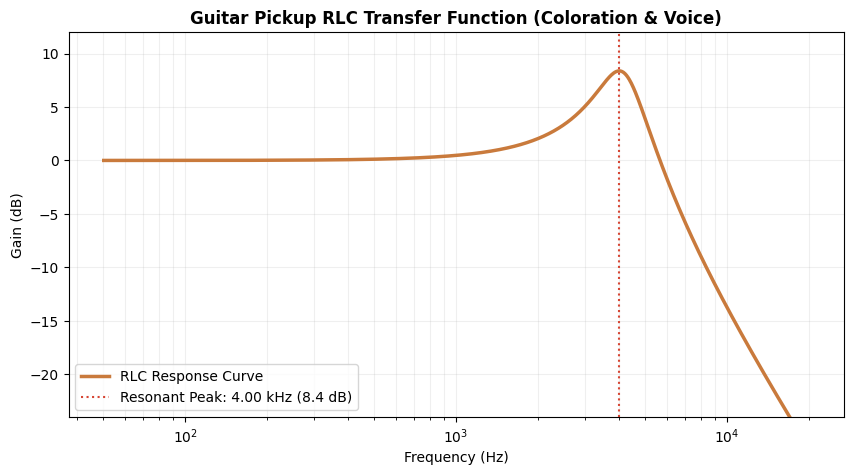

In [15]:
#@title Interactive Pickup RLC Frequency Response Simulator
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as w

def simulate_rlc(L_henries, R_dc_kohm, C_cable_pf, R_pot_kohm):
    f = np.logspace(1.7, 4.3, 1000)  # Frequency spectrum (approx 50 Hz to 20 kHz)
    w_rad = 2 * np.pi * f
    s = 1j * w_rad

    # Convert units
    R_dc = R_dc_kohm * 1e3
    L = L_henries
    C = (100 + C_cable_pf) * 1e-12  # Adding 100 pF of internal parasitic winding capacitance
    R_pot = R_pot_kohm * 1e3

    # Calculate Transfer Function H(s)
    numerator = 1.0
    denominator = L * C * s**2 + (R_dc * C + L / R_pot) * s + (1.0 + R_dc / R_pot)
    H = numerator / denominator

    # Convert response to Decibels (normalized to DC output)
    H_normalized = H / (1.0 / (1.0 + R_dc / R_pot))
    magnitude_db = 20 * np.log10(np.abs(H_normalized))

    # Find resonant frequency peak
    idx_peak = np.argmax(magnitude_db)
    f_res = f[idx_peak]
    peak_db = magnitude_db[idx_peak]

    plt.figure(figsize=(10, 5))
    plt.semilogx(f, magnitude_db, color='#c97a3c', lw=2.5, label='RLC Response Curve')
    plt.axvline(f_res, color='#d64533', linestyle=':', label=f'Resonant Peak: {f_res/1e3:.2f} kHz ({peak_db:.1f} dB)')

    plt.title("Guitar Pickup RLC Transfer Function (Coloration & Voice)", fontsize=12, fontweight='bold')
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Gain (dB)")
    plt.ylim(-24, 12)
    plt.grid(True, which="both", ls="-", alpha=0.2)
    plt.legend(loc="lower left")
    plt.show()

w.interact(simulate_rlc,
           L_henries=w.FloatSlider(min=1.5, max=9.0, step=0.5, value=2.5, description="Inductance (H)"),
           R_dc_kohm=w.FloatSlider(min=4.0, max=16.0, step=0.5, value=6.5, description="Resistance (kΩ)"),
           C_cable_pf=w.IntSlider(min=50, max=1500, step=50, value=400, description="Cable Cap (pF)"),
           R_pot_kohm=w.SelectionSlider(options=[100, 250, 500, 1000], value=250, description="Vol Pot (kΩ)"))

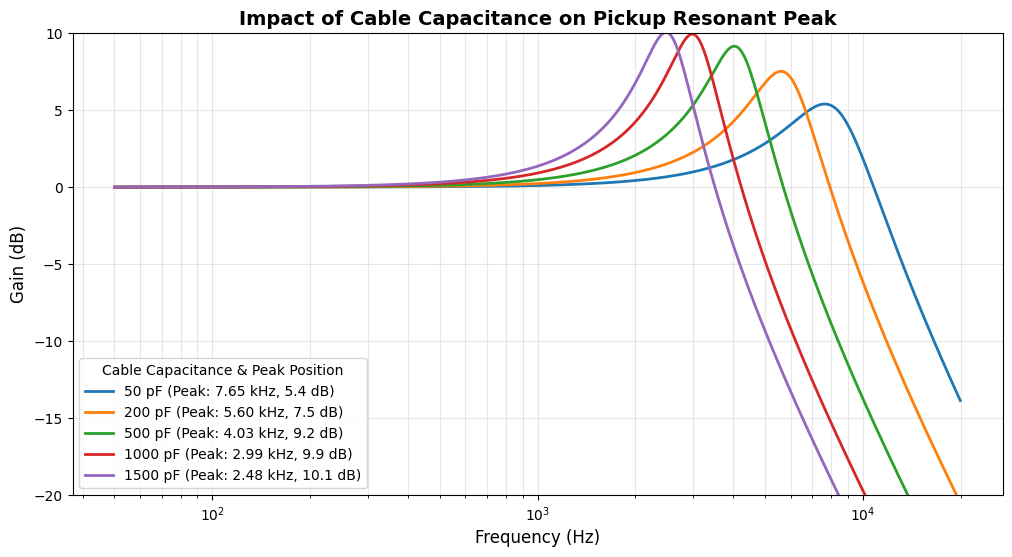

In [16]:
import numpy as np
import matplotlib.pyplot as plt

# Fixed typical pickup parameters
L = 2.5           # Inductance (Henries)
R_dc = 6.5 * 1e3  # DC Resistance (Ohms)
R_pot = 250 * 1e3 # Potentiometer Resistance (Ohms)
C_internal = 100e-12 # Parasitic winding capacitance (100 pF)

# Define common cable capacitance values to sweep
# (e.g., short patch cable, standard 10ft cable, long stage cable)
cable_capacitances = [50, 200, 500, 1000, 1500] # in pF

f = np.logspace(1.7, 4.3, 1000)  # Frequency spectrum (approx 50 Hz to 20 kHz)
w_rad = 2 * np.pi * f
s = 1j * w_rad

plt.figure(figsize=(12, 6))

for C_cable_pf in cable_capacitances:
    C_total = C_internal + (C_cable_pf * 1e-12)

    # Calculate Transfer Function H(s)
    numerator = 1.0
    denominator = L * C_total * s**2 + (R_dc * C_total + L / R_pot) * s + (1.0 + R_dc / R_pot)
    H = numerator / denominator

    # Normalize to DC Gain
    H_normalized = H / (1.0 / (1.0 + R_dc / R_pot))
    magnitude_db = 20 * np.log10(np.abs(H_normalized))

    # Locate peak
    idx_peak = np.argmax(magnitude_db)
    f_res = f[idx_peak]
    peak_db = magnitude_db[idx_peak]

    # Plot response curve
    label_txt = f"{C_cable_pf} pF (Peak: {f_res/1e3:.2f} kHz, {peak_db:.1f} dB)"
    plt.semilogx(f, magnitude_db, lw=2, label=label_txt)

plt.title("Impact of Cable Capacitance on Pickup Resonant Peak", fontsize=14, fontweight='bold')
plt.xlabel("Frequency (Hz)", fontsize=12)
plt.ylabel("Gain (dB)", fontsize=12)
plt.ylim(-20, 10)
plt.grid(True, which="both", ls="-", alpha=0.3)
plt.legend(title="Cable Capacitance & Peak Position", fontsize=10, loc="lower left")
plt.show()

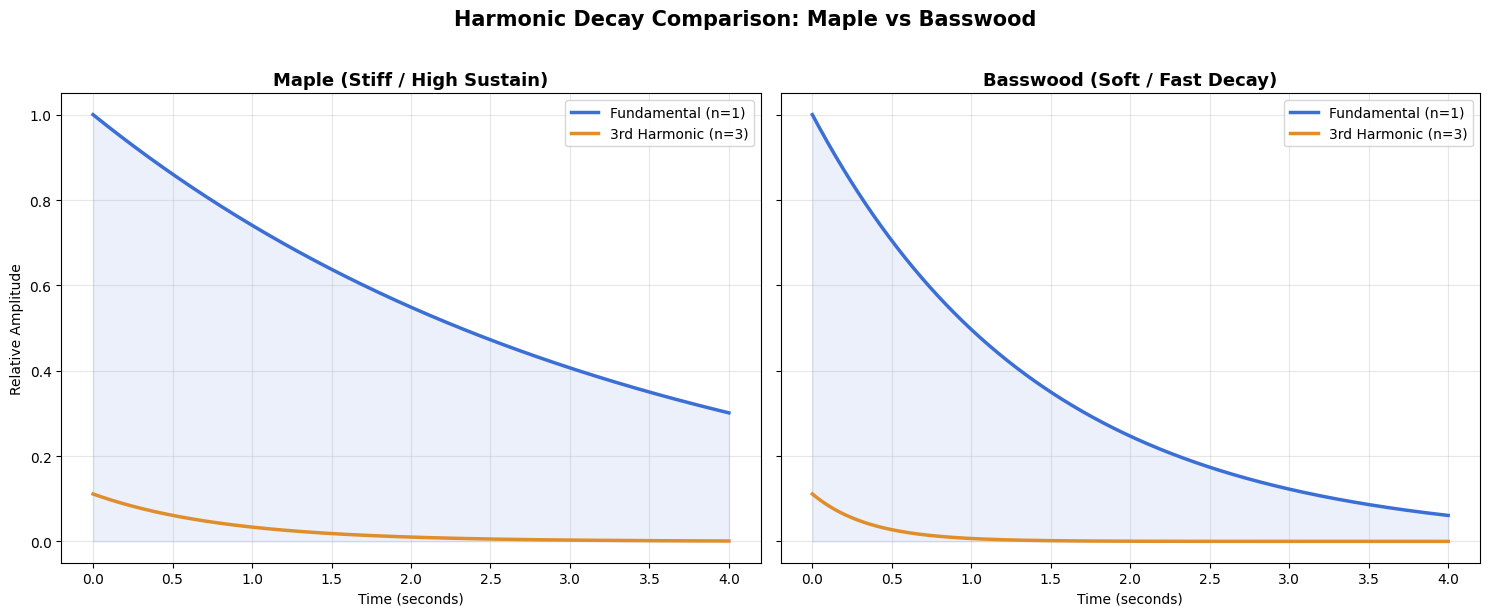

In [17]:
import numpy as np
import matplotlib.pyplot as plt

t = np.linspace(0, 4.0, 1000)

# Dynamic profiles from our established model:
# Maple: [gamma1, gamma2, gamma3, gamma4] = [0.3, 0.6, 1.2, 2.5]
# Basswood: [gamma1, gamma2, gamma3, gamma4] = [0.7, 1.5, 2.8, 5.0]

maple_damps = [0.3, 0.6, 1.2, 2.5]
basswood_damps = [0.7, 1.5, 2.8, 5.0]

# Fundamental (n=1) and 3rd Harmonic (n=3) initial amplitudes
a1_init = 1.0
a3_init = 1.0 / 9.0

# Calculate individual harmonic decay curves
maple_n1 = a1_init * np.exp(-maple_damps[0] * t)
maple_n3 = a3_init * np.exp(-maple_damps[2] * t)

basswood_n1 = a1_init * np.exp(-basswood_damps[0] * t)
basswood_n3 = a3_init * np.exp(-basswood_damps[2] * t)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

# Left Plot: Maple decay
ax1.plot(t, maple_n1, label="Fundamental (n=1)", color="#3b6fd6", lw=2.5)
ax1.plot(t, maple_n3, label="3rd Harmonic (n=3)", color="#e08e2b", lw=2.5)
ax1.fill_between(t, 0, maple_n1, color="#3b6fd6", alpha=0.1)
ax1.set_title("Maple (Stiff / High Sustain)", fontsize=13, fontweight='bold')
ax1.set_xlabel("Time (seconds)")
ax1.set_ylabel("Relative Amplitude")
ax1.grid(True, alpha=0.3)
ax1.legend()

# Right Plot: Basswood decay
ax2.plot(t, basswood_n1, label="Fundamental (n=1)", color="#3b6fd6", lw=2.5)
ax2.plot(t, basswood_n3, label="3rd Harmonic (n=3)", color="#e08e2b", lw=2.5)
ax2.fill_between(t, 0, basswood_n1, color="#3b6fd6", alpha=0.1)
ax2.set_title("Basswood (Soft / Fast Decay)", fontsize=13, fontweight='bold')
ax2.set_xlabel("Time (seconds)")
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.suptitle("Harmonic Decay Comparison: Maple vs Basswood", fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 5.1.2 Side-by-Side Decay Analysis

The following script isolates and displays the decay envelopes of both Maple and Basswood, emphasizing how different mechanical systems act on the 1st (Fundamental) and 3rd harmonics of a vibrating string.

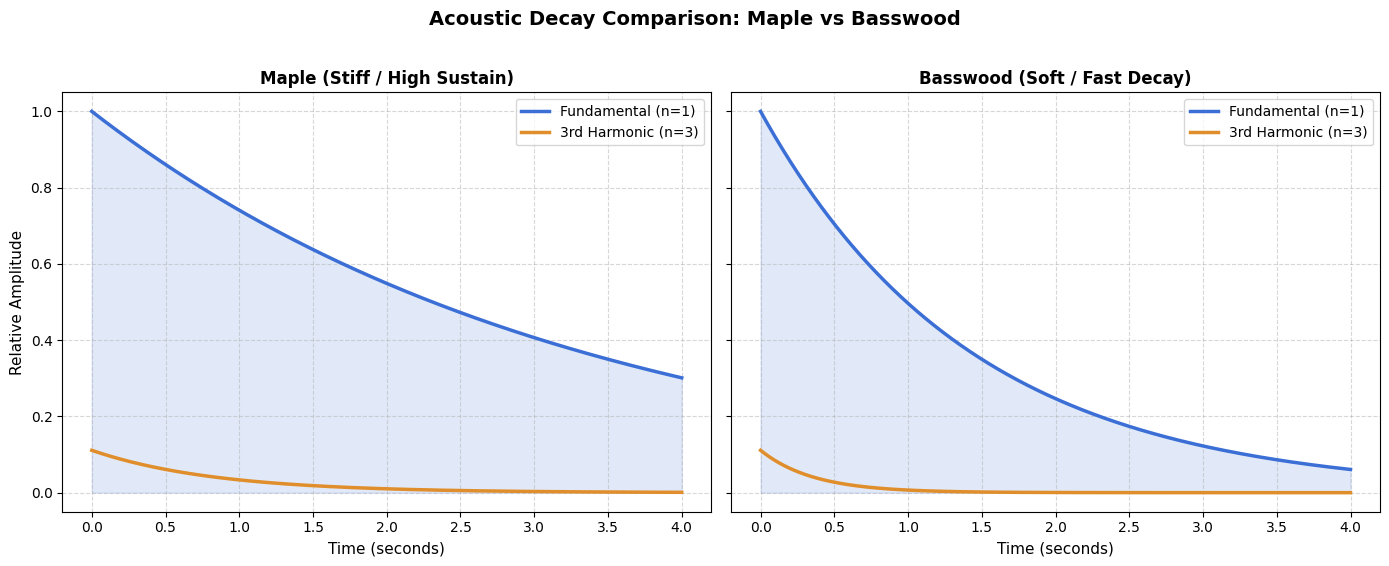

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# Define common time vector (0 to 4 seconds)
t_vec = np.linspace(0, 4.0, 1000)

# Dynamic profiles from our physical model:
# Maple: [gamma1, gamma2, gamma3, gamma4] = [0.3, 0.6, 1.2, 2.5]
# Basswood: [gamma1, gamma2, gamma3, gamma4] = [0.7, 1.5, 2.8, 5.0]
maple_gammas = [0.3, 1.2]     # Fundamental (n=1) and 3rd harmonic (n=3)
basswood_gammas = [0.7, 2.8]  # Fundamental (n=1) and 3rd harmonic (n=3)

# Harmonics amplitudes (using 1/n^2 pluck conditions)
amp_n1 = 1.0
amp_n3 = 1.0 / 9.0

# Calculate exponential decay curves
maple_fundamental = amp_n1 * np.exp(-maple_gammas[0] * t_vec)
maple_harmonic_3 = amp_n3 * np.exp(-maple_gammas[1] * t_vec)

basswood_fundamental = amp_n1 * np.exp(-basswood_gammas[0] * t_vec)
basswood_harmonic_3 = amp_n3 * np.exp(-basswood_gammas[1] * t_vec)

# Create side-by-side subplot
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)

# Left Panel: Maple
axes[0].plot(t_vec, maple_fundamental, label="Fundamental (n=1)", color="#3b6fd6", lw=2.5)
axes[0].plot(t_vec, maple_harmonic_3, label="3rd Harmonic (n=3)", color="#e08e2b", lw=2.5)
axes[0].fill_between(t_vec, 0, maple_fundamental, color="#3b6fd6", alpha=0.15)
axes[0].set_title("Maple (Stiff / High Sustain)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Time (seconds)", fontsize=11)
axes[0].set_ylabel("Relative Amplitude", fontsize=11)
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].legend(loc="upper right", fontsize=10)

# Right Panel: Basswood
axes[1].plot(t_vec, basswood_fundamental, label="Fundamental (n=1)", color="#3b6fd6", lw=2.5)
axes[1].plot(t_vec, basswood_harmonic_3, label="3rd Harmonic (n=3)", color="#e08e2b", lw=2.5)
axes[1].fill_between(t_vec, 0, basswood_fundamental, color="#3b6fd6", alpha=0.15)
axes[1].set_title("Basswood (Soft / Fast Decay)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Time (seconds)", fontsize=11)
axes[1].grid(True, linestyle="--", alpha=0.5)
axes[1].legend(loc="upper right", fontsize=10)

plt.suptitle("Acoustic Decay Comparison: Maple vs Basswood", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()